In [1]:
import torch
import torchvision
from torchvision.transforms import v2

In [84]:
transform=v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

batch_size = 32

trainset=torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader=torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset=torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

classes = ('plane', 'car', 'bird', 'cat',
            'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


In [101]:
import torch

# Define device dynamically (uses GPU if available, else falls back to CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda


In [102]:
testloader=torch.utils.data.DataLoader(testset, batch_size= batch_size, shuffle=True, num_workers=4)

classes = ('plane', 'car', 'bird', 'cat',
            'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


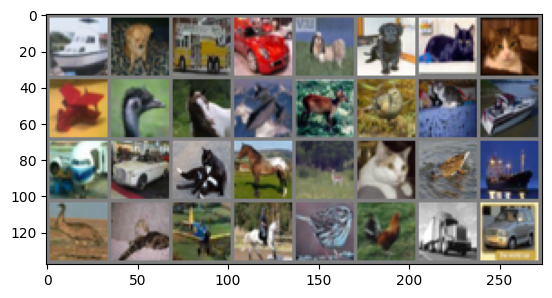

ship  dog   truck car   dog   dog   cat   cat   plane bird  horse plane deer  bird  cat   ship  plane car   cat   horse deer  cat   bird  ship  bird  cat   plane horse bird  bird  truck car  


In [87]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
  img= img/2+0.5
  npimg=img.numpy()
  plt.imshow(np.transpose(npimg, (1,2,0)))
  plt.show()
dataiter=iter(trainloader)
images, labels=next(dataiter)

imshow(torchvision.utils.make_grid(images))
print(' '.join(f"{classes[labels[j]]:5s}" for j in range(batch_size)))


In [103]:
from torch import nn
import torch.nn.functional as F

class Net(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(3,6,5)
    self.pool = nn.MaxPool2d(2,2)
    self.conv2 = nn.Conv2d(6,32,5)
    self.conv3 = nn.Conv2d(32,16,5)
    self.fc1 = nn.Linear(32*5*5, 400)
    self.fc2 = nn.Linear(400, 250)
    self.fc3 = nn.Linear(250,100)
    self.fc4 = nn.Linear(100,10)

  def forward(self,x):
    x=self.pool(F.relu(self.conv1(x)))
    x=self.pool(F.relu(self.conv2(x)))
    x=torch.flatten(x,1)
    x=F.relu(self.fc1(x))
    x=F.relu(self.fc2(x))
    x=F.relu(self.fc3(x))
    x=self.fc4(x)
    return x


net = Net()

In [104]:
import torch.optim as optim
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum = 0.9)
net=net.to(device)


In [105]:
for epoch in range(10):
  running_loss= 0.0
  for i, data in enumerate(trainloader, 0):
    inputs, labels = data

    # Zeroing the parameter gradients
    optimizer.zero_grad()

    # forward, backward and then optimize
    outputs=net(inputs)
    loss=criterion(outputs,labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
    if i%2000 == 0:
      print(f"Epoch: {epoch+1}, Batch: {i/2000}, Loss: {running_loss/2000:0.6f}")
      running_loss=0.0
print("Finished Training")


Epoch: 1, Batch:   500, Loss: 2.303155
Epoch: 1, Batch:  1000, Loss: 2.301045
Epoch: 1, Batch:  1500, Loss: 2.297150
Epoch: 2, Batch:   500, Loss: 2.272920
Epoch: 2, Batch:  1000, Loss: 2.105461
Epoch: 2, Batch:  1500, Loss: 1.958339
Epoch: 3, Batch:   500, Loss: 1.840773
Epoch: 3, Batch:  1000, Loss: 1.720964
Epoch: 3, Batch:  1500, Loss: 1.637209
Epoch: 4, Batch:   500, Loss: 1.564220
Epoch: 4, Batch:  1000, Loss: 1.526572
Epoch: 4, Batch:  1500, Loss: 1.480997
Epoch: 5, Batch:   500, Loss: 1.435209
Epoch: 5, Batch:  1000, Loss: 1.414973
Epoch: 5, Batch:  1500, Loss: 1.368318
Epoch: 6, Batch:   500, Loss: 1.327447
Epoch: 6, Batch:  1000, Loss: 1.311458
Epoch: 6, Batch:  1500, Loss: 1.294436
Epoch: 7, Batch:   500, Loss: 1.265224
Epoch: 7, Batch:  1000, Loss: 1.231858
Epoch: 7, Batch:  1500, Loss: 1.211060
Epoch: 8, Batch:   500, Loss: 1.170047
Epoch: 8, Batch:  1000, Loss: 1.169040
Epoch: 8, Batch:  1500, Loss: 1.157067
Epoch: 9, Batch:   500, Loss: 1.103911
Epoch: 9, Batch:  1000, L

In [106]:
PATH = './cifar_net_experimental.pt'
torch.save(net.state_dict(), PATH)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


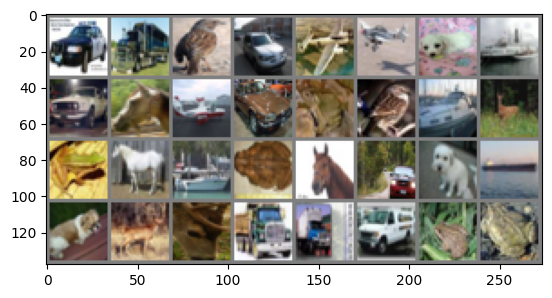

car truck bird car plane plane dog ship car horse plane car frog bird ship deer frog horse ship frog horse car dog ship dog deer deer truck truck truck frog frog


In [107]:
dataiter=iter(testloader)
images, labels = next(dataiter)
imshow(torchvision.utils.make_grid(images))
print(" ".join(f"{classes[labels[j]]}" for j in range(batch_size)))



In [108]:
net = Net()
net.load_state_dict(torch.load(PATH,weights_only=True))

<All keys matched successfully>

In [109]:
correct=0
total=0
with torch.no_grad():
  for data in testloader:
    images, labels = data
    outputs=net(images)
    _, predicted = torch.max(outputs,1)
    total+=labels.size(0)
    correct+= (predicted == labels).sum().item()

print(f"Accuracy of the model on {total} images: {(correct/total)*100}%")


Accuracy of the model on 10000 images: 61.17%
